In [5]:
!pip install ucimlrepo

In [9]:
from ucimlrepo import fetch_ucirepo  # Fetches datasets from UCI ML Repository
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [15]:
# 1. Fetch the Dataset
# ------------------------------
# Dataset ID 17 corresponds to the Breast Cancer Wisconsin (Diagnostic) dataset.
breast_cancer_wisconsin_diagnostic = fetch_ucirepo(id=17)

# Extract data (as pandas DataFrames)
X = breast_cancer_wisconsin_diagnostic.data.features
y = breast_cancer_wisconsin_diagnostic.data.targets

# Print metadata and variable information for exploration
print("Dataset Metadata:")
print(breast_cancer_wisconsin_diagnostic.metadata, "\n")
print("Variable Information:")
print(breast_cancer_wisconsin_diagnostic.variables, "\n")

# Convert X and y to NumPy arrays (if they are DataFrames/Series)
X = X.values if hasattr(X, "values") else X
y = y.values if hasattr(y, "values") else y

# ------------------------------
#  Split and Preprocess the Data
# ------------------------------
# Split data into training and test sets (80:20 split)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)


Dataset Metadata:
{'uci_id': 17, 'name': 'Breast Cancer Wisconsin (Diagnostic)', 'repository_url': 'https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic', 'data_url': 'https://archive.ics.uci.edu/static/public/17/data.csv', 'abstract': 'Diagnostic Wisconsin Breast Cancer Database.', 'area': 'Health and Medicine', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 569, 'num_features': 30, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['Diagnosis'], 'index_col': ['ID'], 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1993, 'last_updated': 'Fri Nov 03 2023', 'dataset_doi': '10.24432/C5DW2B', 'creators': ['William Wolberg', 'Olvi Mangasarian', 'Nick Street', 'W. Street'], 'intro_paper': {'ID': 230, 'type': 'NATIVE', 'title': 'Nuclear feature extraction for breast tumor diagnosis', 'authors': 'W. Street, W. Wolberg, O. Mangasarian', 'venue': 'Electronic imaging', 'year': 1993, 'journal

In [16]:
# 2. Reshape y_train and y_test to be 1D arrays
y_train = y_train.ravel()
y_test = y_test.ravel()

# Standardize the features (zero mean, unit variance)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [17]:
# 3. Model Building with SVM and Hyperparameter Tuning
# ------------------------------
# Define a parameter grid for SVM (using the RBF kernel)
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': [1, 0.1, 0.01, 0.001],
    'kernel': ['rbf']
}

# Use GridSearchCV with 5-fold cross-validation to find the best parameters
grid = GridSearchCV(SVC(), param_grid, refit=True, cv=5, verbose=2)
grid.fit(X_train_scaled, y_train)

print("Best Parameters Found:")
print(grid.best_params_)

Fitting 5 folds for each of 16 candidates, totalling 80 fits
[CV] END .........................C=0.1, gamma=1, kernel=rbf; total time=   0.0s
[CV] END .........................C=0.1, gamma=1, kernel=rbf; total time=   0.0s
[CV] END .........................C=0.1, gamma=1, kernel=rbf; total time=   0.0s
[CV] END .........................C=0.1, gamma=1, kernel=rbf; total time=   0.0s
[CV] END .........................C=0.1, gamma=1, kernel=rbf; total time=   0.0s
[CV] END .......................C=0.1, gamma=0.1, kernel=rbf; total time=   0.0s
[CV] END .......................C=0.1, gamma=0.1, kernel=rbf; total time=   0.0s
[CV] END .......................C=0.1, gamma=0.1, kernel=rbf; total time=   0.0s
[CV] END .......................C=0.1, gamma=0.1, kernel=rbf; total time=   0.0s
[CV] END .......................C=0.1, gamma=0.1, kernel=rbf; total time=   0.0s
[CV] END ......................C=0.1, gamma=0.01, kernel=rbf; total time=   0.0s
[CV] END ......................C=0.1, gamma=0.01

In [18]:
# 4. Evaluate the Model
# ------------------------------
# Predict on the test set
y_pred = grid.predict(X_test_scaled)

# Calculate accuracy and display a classification report
accuracy = accuracy_score(y_test, y_pred)
print(f"\nTest Accuracy: {accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))


Test Accuracy: 0.9825

Classification Report:
              precision    recall  f1-score   support

           B       0.97      1.00      0.99        71
           M       1.00      0.95      0.98        43

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



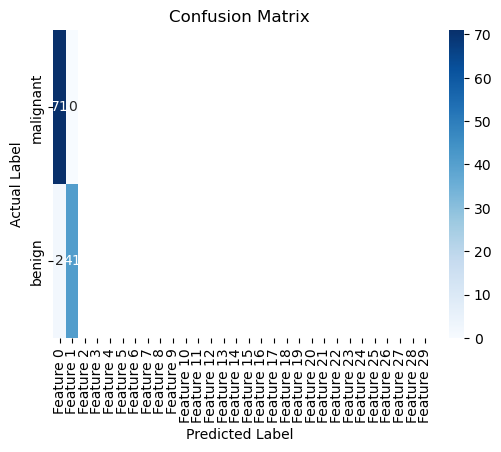

In [19]:
# Plot the confusion matrix
if hasattr(X, "columns"):
    xtick_labels = X.columns
else:
    xtick_labels = [f"Feature {i}" for i in range(X.shape[1])]
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=xtick_labels,
            yticklabels=["malignant", "benign"])
plt.ylabel("Actual Label")
plt.xlabel("Predicted Label")
plt.title("Confusion Matrix")
plt.show()

In [26]:
from sklearn.pipeline import Pipeline
import joblib  

pipeline = Pipeline([
    ('scaler', scaler),
    ('svm', grid.best_estimator_)
])
joblib.dump(pipeline, 'breast_cancer_classifier.pkl')
print("Model saved as 'breast_cancer_classifier.pkl'")
joblib.load('breast_cancer_classifier.pkl') 

Model saved as 'breast_cancer_classifier.pkl'


Pipeline(steps=[('scaler', StandardScaler()), ('svm', SVC(C=100, gamma=0.001))])

In [28]:

# Load the saved classifier
breast_cancer_classifier = joblib.load('breast_cancer_classifier.pkl')

# Define your input data (a tuple of 30 feature values)
input_data = (13.54,14.36,87.46,566.3,0.09779,0.08129,0.06664,0.04781,0.1885,
              0.05766,0.2699,0.7886,2.058,23.56,0.008462,0.0146,0.02387,
              0.01315,0.0198,0.0023,15.11,19.26,99.7,711.2,0.144,0.1773,
              0.239,0.1288,0.2977,0.07259)

# Convert the input data to a NumPy array
input_data_as_numpy_array = np.asarray(input_data)

# Reshape the data to match the model input (1 sample with 30 features)
input_data_reshaped = input_data_as_numpy_array.reshape(1, -1)

# Make the prediction
prediction = breast_cancer_classifier.predict(input_data_reshaped)
print(prediction)

if prediction[0] == 0:
    print('The Breast cancer is Malignant')
else:
    print('The Breast Cancer is Benign')


['B']
The Breast Cancer is Benign
